# Feature Importance Analyses for Mislocalization

In [166]:
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import umap
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random

controls = {
    "TC": ["EGFP"],
    "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
    "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
    # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
    # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
    # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
    # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
}

ctrl_alleles = [k_v for k_v in controls.values()]
ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# ctrl_alleles_flat

np.random.seed(42)
random.seed(42)

## Load feature importance and classifier info

### Feature importance from two batches

In [140]:
classifier_raw_input_dir = [
    "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/results/2024_01_23_Batch_7/profiles_tcdropped_filtered_var_mad_outlier_featselect",
    "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/results/2024_02_06_Batch_8/profiles_tcdropped_filtered_var_mad_outlier_featselect"
]

feat_dfs = pl.DataFrame()
for batch_dir in classifier_raw_input_dir:
    # Read the data
    feat_df = pl.read_csv(f"{batch_dir}/feat_importance.csv")
    gfp_cols = ["Group1", "Group2"] + [col for col in feat_df.columns if "GFP" in col]
    feat_df = feat_df.select(
        gfp_cols
    ).with_columns(
        pl.lit(batch_dir.split('/')[-2]).alias("batch")
    )
    # print(feat_df)
    feat_dfs = pl.concat([feat_dfs, feat_df], how="diagonal")

### Filter the GFP cols

Filter the cols with all nulls and get the mean feature importance per column

In [181]:
# Filter out columns where all values are null
non_null_cols = [col for col in feat_dfs.columns if not feat_dfs[col].is_null().all()]
feat_df_clean = feat_dfs.select(non_null_cols)

# Group by "Group1" and "Group2" and compute the mean for all columns except "batch"
feat_df_mean = feat_df_clean.group_by(["Group1", "Group2"]).agg( ## , "batch"
    pl.col("*").exclude(["Group1", "Group2", "batch"]).mean()
)
# Filter out columns where any values are null
meta_cols = [col for col in feat_df_mean.columns if "GFP" not in col]
gfp_cols = [col for col in feat_df_mean.columns if "GFP" in col]
no_null_gfp_cols = [col for col in gfp_cols if not feat_df_mean[col].is_nan().any() and not feat_df_mean[col].is_null().any()]

feat_df_mean = feat_df_mean.select(meta_cols+no_null_gfp_cols).with_columns(
    pl.when(pl.col("Group1").is_in(ctrl_alleles_flat))
    .then(pl.lit("Control"))
    .otherwise(pl.lit("Allele"))
    .alias("Variant_Type")
)
# feat_df_mean

### Mislocalization results

In [148]:
# integrative_inputs = "../../../../3_integrated_assay_results/1_inputs"
# scores = pl.read_csv(f"{integrative_inputs}/misloc_scores.csv")
# scores

trn_imbalance_thresh = 3

# Paths
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")

    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])

## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")
## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()
misloc_alleles = (
    local_wtvar
    .select("allele_0")
    .to_series()
    .to_list()
)

## get individual classifiers pass the training imbalance threshold
ind_class = metrics_df.filter(
    (~pl.col("Metadata_Control"))
    & (pl.col("Training_imbalance") < trn_imbalance_thresh)
    & (
        (pl.col("Full_Classifier_ID").str.contains("true"))
        & pl.col("allele_0").is_in(misloc_alleles)
    )
)

misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        columns="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        )
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
    .filter(pl.col("allele_0").is_in(ind_class["allele_0"]))
)

sig_misloc_alleles = misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]

In [150]:
feat_df_mean_pd = feat_df_mean.to_pandas()
feat_df_mean_pd["Allele"] = feat_df_mean_pd["Group2"].apply(lambda x: '_'.join(x.split("_")[1:]) if "_" in x else x)

## get the three classes of variants/alleles
feat_df_mean_pd_misloc_var = feat_df_mean_pd[feat_df_mean_pd["Allele"].isin(sig_misloc_alleles)]
feat_df_mean_pd_no_misloc_var = feat_df_mean_pd[~feat_df_mean_pd["Allele"].isin(sig_misloc_alleles)]
feat_df_mean_pd_ctrl_alleles = feat_df_mean_pd[feat_df_mean_pd["Variant_Type"]=="Control"][feat_df_mean_pd_misloc_var.columns]

## Important Features

### Visualize the top N (default n=10) most important features

In [152]:
def plot_top_n_important_feat(df, n=10, ax=None, title=""):
    # Calculate mean and standard deviation for each column
    column_stats = df[[col for col in df.columns if "GFP" in col]].agg(['mean', 'std']).T

    # Sort columns by the sum of mean and std in descending order
    sorted_columns = column_stats.sort_values(by=["mean"], ascending=False)
    sorted_columns = sorted_columns.head(n)
    # display(sorted_columns)

    # Plot mean and std for each column
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    ax.barh(y=sorted_columns.index, width=sorted_columns["mean"], color='skyblue') ## yerr=sorted_columns["std"], capsize=5, edgecolor='black'
    ax.set_yticks(range(len(sorted_columns.index)))
    ax.set_yticklabels(sorted_columns.index, rotation=0, fontsize=8)
    # ax.set_xlabel("Mean")
    ax.set_title(f"Features Importance Mean {title}")
    ax.axvline(x=0.01, color='r', linestyle='--')
    # plt.tight_layout()
    # plt.show()
    return sorted_columns

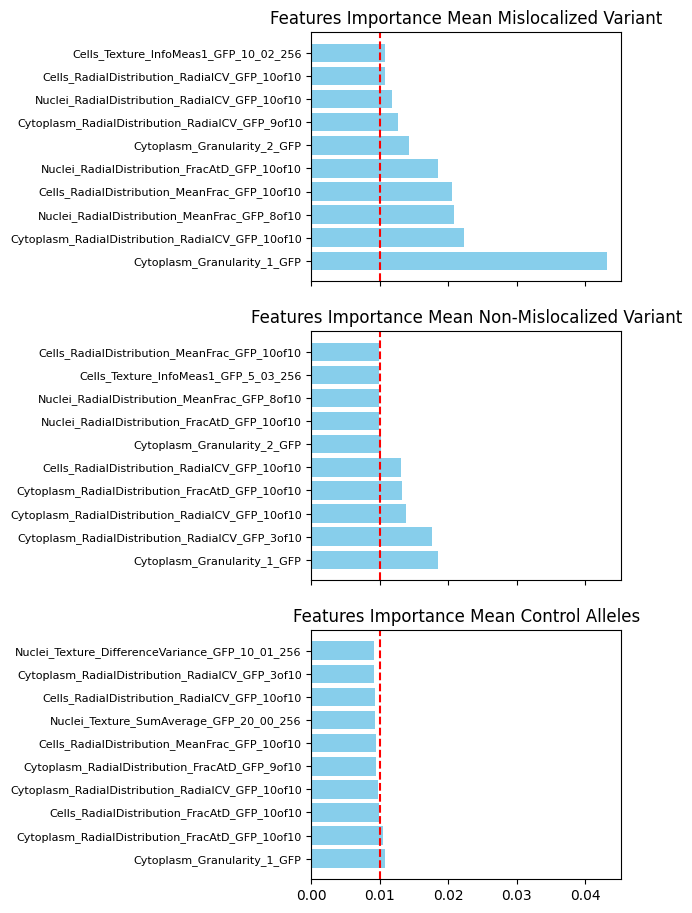

In [155]:
fig, axes = plt.subplots(3,1, figsize=(4, 11), sharex=True)
feat_import_ctrl = plot_top_n_important_feat(feat_df_mean_pd_misloc_var, ax=axes[0], title="Mislocalized Variant")
feat_import_misloc_var = plot_top_n_important_feat(feat_df_mean_pd_no_misloc_var, ax=axes[1], title="Non-Mislocalized Variant")
feat_import_misloc_var = plot_top_n_important_feat(feat_df_mean_pd_ctrl_alleles, ax=axes[2], title="Control Alleles")

## DR based on feature importance

### All variants and alleles

Text(0.5, 0.97, 'PCA and UMAP of All Variants')

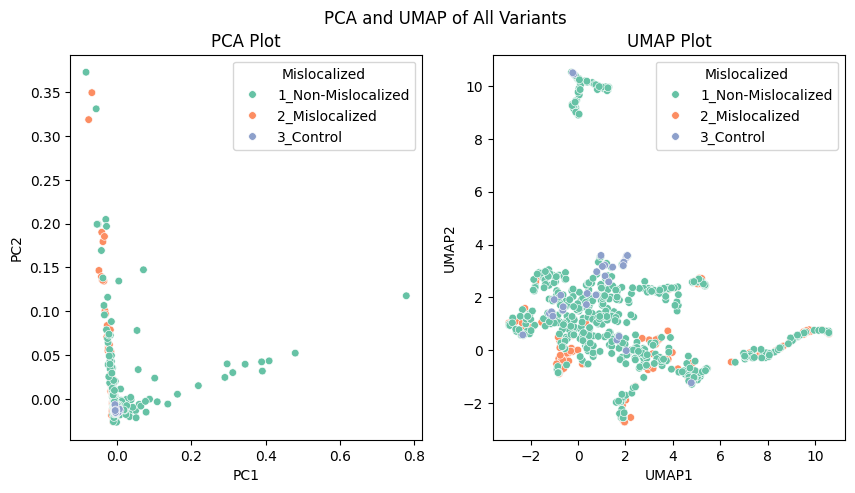

In [179]:
set2_palette = sns.color_palette("Set2", n_colors=3)

feat_df_mean_pd_misloc_var.loc[:,"Mislocalized"] = "2_Mislocalized"
feat_df_mean_pd_no_misloc_var.loc[:,"Mislocalized"] = "1_Non-Mislocalized"
feat_df_mean_pd_ctrl_alleles.loc[:,"Mislocalized"] = "3_Control"

feat_df_mean_pd_misloc_var_ctrl = pd.concat([feat_df_mean_pd_misloc_var, feat_df_mean_pd_no_misloc_var, feat_df_mean_pd_ctrl_alleles], ignore_index=True)
# display(feat_df_mean_pd_misloc_var_ctrl)

## Select the features based on the top n important features
numeric_cols = feat_df_mean_pd_misloc_var_ctrl.loc[:,feat_import_misloc_var.index]

# Standardize the features before PCA
# scaler = StandardScaler()
# numeric_cols = pd.DataFrame(scaler.fit_transform(numeric_cols), columns=numeric_cols.columns)

variant_type = feat_df_mean_pd_misloc_var_ctrl["Mislocalized"]
group2_labels = feat_df_mean_pd_misloc_var_ctrl["Allele"]

# Perform PCA
pca = PCA(n_components=10)
pca_result = pca.fit_transform(numeric_cols)

# Plot PCA
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=variant_type, palette=set2_palette, s=30, ax=ax[0], hue_order=["1_Non-Mislocalized", "2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     # if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#     texts.append(ax[0].text(pca_result[i, 0], pca_result[i, 1], label, 
#                     fontsize=8, fontweight='bold', color='black'))
# # print(texts)
# adjust_text(texts, expand_points=(4, 4), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 
ax[0].set_title("PCA Plot")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(numeric_cols)

sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=variant_type, palette=set2_palette, s=30, ax=ax[1], hue_order=["1_Non-Mislocalized", "2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     texts.append(ax[1].text(umap_result[i, 0], umap_result[i, 1], label, 
#                     fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1]) ## 
ax[1].set_title("UMAP Plot")
ax[1].set_xlabel("UMAP1")
ax[1].set_ylabel("UMAP2")
plt.suptitle("PCA and UMAP of All Variants", y=.97)

### Compare mislocalized variants vs control alleles

,Group1,Group2,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_10_03_256,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cytoplasm_Texture_Correlation_GFP_20_03_256,Cells_RadialDistribution_MeanFrac_GFP_5of10,...,Nuclei_Texture_DifferenceVariance_GFP_10_01_256,Cells_RadialDistribution_MeanFrac_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Texture_InfoMeas1_GFP_10_02_256,Nuclei_RadialDistribution_FracAtD_GFP_2of10,Cells_Texture_InfoMeas1_GFP_5_01_256,Variant_Type,Allele,Mislocalized
0,RP2,RP2_RP2_Cys86Tyr,0.003568,0.003720,0.030162,0.007513,0.012057,0.006574,0.007932,0.008201,...,0.005539,0.035031,0.005381,0.003143,0.001124,0.003167,0.004764,Allele,RP2_Cys86Tyr,2_Mislocalized
1,EMD,EMD_EMD_Ala56Thr,0.018178,0.004732,0.009216,0.004946,0.005433,0.001923,0.004330,0.004775,...,0.000818,0.005973,0.006196,0.005358,0.014984,0.005897,0.010204,Allele,EMD_Ala56Thr,2_Mislocalized
2,GMPPB,GMPPB_GMPPB_Asp27His,0.003397,0.003515,0.307710,0.008668,0.004971,0.005161,0.004635,0.014307,...,0.007763,0.008403,0.015670,0.001684,0.002622,0.008560,0.001134,Allele,GMPPB_Asp27His,2_Mislocalized
3,TH,TH_TH_Pro121Leu,0.003509,0.010410,0.004029,0.005214,0.003009,0.002340,0.001672,0.002578,...,0.007616,0.004197,0.003195,0.000000,0.000073,0.003329,0.034768,Allele,TH_Pro121Leu,2_Mislocalized
4,PLA2G6,PLA2G6_PLA2G6_Leu481Gln,0.005488,0.002220,0.001356,0.010028,0.004030,0.005699,0.003973,0.003462,...,0.001410,0.002080,0.007349,0.000000,0.000000,0.006923,0.000207,Allele,PLA2G6_Leu481Gln,2_Mislocalized
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,MAPK9,L13_L14,0.005438,0.007888,0.009700,0.008036,0.008637,0.008598,0.007639,0.008341,...,0.007481,0.008517,0.009051,0.009530,0.005301,0.008191,0.006902,Control,L14,3_Control
149,RHEB,I15_I16,0.007216,0.008223,0.009235,0.007341,0.008556,0.006918,0.007696,0.009592,...,0.009011,0.007220,0.007737,0.008042,0.008758,0.008158,0.008421,Control,I16,3_Control
150,PRKACB,E19_F19,0.008651,0.007755,0.010628,0.008011,0.009434,0.007833,0.007777,0.008462,...,0.011569,0.007717,0.009054,0.008077,0.009106,0.007881,0.008470,Control,F19,3_Control
151,MAPK9,K14_L14,0.005135,0.010347,0.010809,0.008098,0.007974,0.006468,0.008248,0.008465,...,0.006504,0.008555,0.009166,0.007708,0.005393,0.008077,0.003219,Control,L14,3_Control


Text(0.5, 0.97, 'PCA and UMAP of Mislocalzed vs Control Variants')

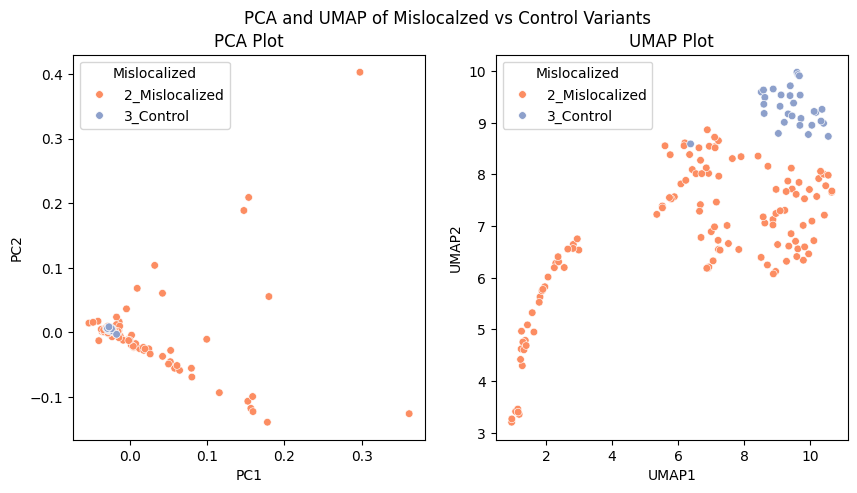

In [180]:
feat_df_mean_pd_misloc_var_ctrl = pd.concat([feat_df_mean_pd_misloc_var, feat_df_mean_pd_ctrl_alleles], ignore_index=True)
display(feat_df_mean_pd_misloc_var_ctrl)

## Select the features based on the top n important features
numeric_cols = feat_df_mean_pd_misloc_var_ctrl.loc[:,feat_import_misloc_var.index]

# Standardize the features before PCA
# scaler = StandardScaler()
# numeric_cols = pd.DataFrame(scaler.fit_transform(numeric_cols), columns=numeric_cols.columns)

variant_type = feat_df_mean_pd_misloc_var_ctrl["Mislocalized"]
group2_labels = feat_df_mean_pd_misloc_var_ctrl["Allele"]

# Perform PCA
pca = PCA(n_components=10)
pca_result = pca.fit_transform(numeric_cols)

# Plot PCA
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=variant_type, palette=set2_palette[1:], s=30, ax=ax[0], hue_order=["2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     # if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#     texts.append(ax[0].text(pca_result[i, 0], pca_result[i, 1], label, 
#                     fontsize=8, fontweight='bold', color='black'))
# # print(texts)
# adjust_text(texts, expand_points=(4, 4), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 
ax[0].set_title("PCA Plot")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(numeric_cols)

sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=variant_type, palette=set2_palette[1:], s=30, ax=ax[1], hue_order=["2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     texts.append(ax[1].text(umap_result[i, 0], umap_result[i, 1], label, 
#                     fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1]) ## 
ax[1].set_title("UMAP Plot")
ax[1].set_xlabel("UMAP1")
ax[1].set_ylabel("UMAP2")
plt.suptitle("PCA and UMAP of Mislocalzed vs Control Variants", y=.97)

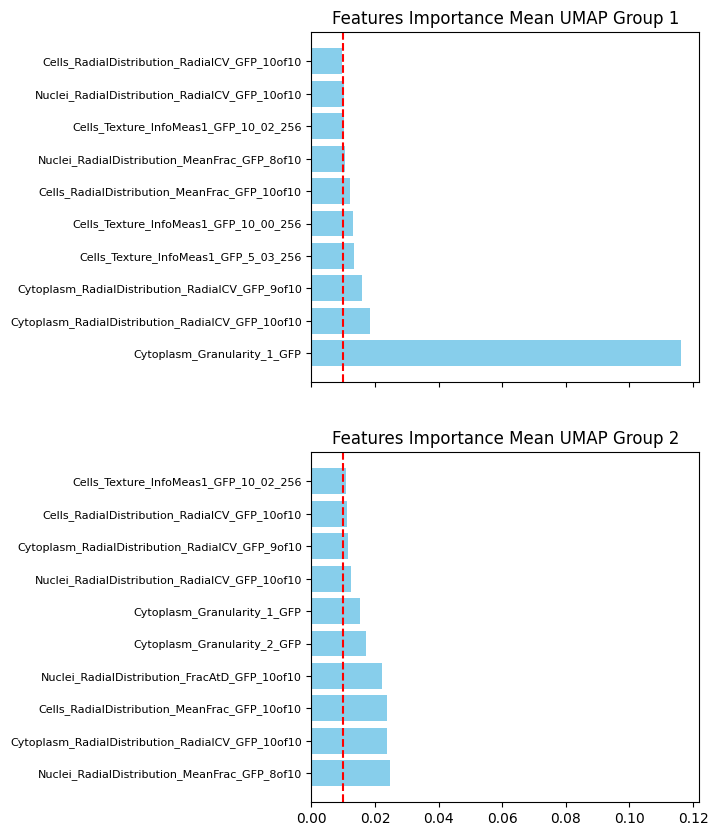

In [173]:
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Variant_Type"] = variant_type.to_list()
umap_df["Group2"] = group2_labels.to_list()
umap_df["Group1"] = feat_df_mean_pd_misloc_var_ctrl["Group1"].to_list()
umap_group1 = umap_df[umap_df["UMAP1"]<4]["Group2"].unique()

fig, axes = plt.subplots(2, 1, figsize=(5, 10), sharex=True)
umap_group1_fi = plot_top_n_important_feat(feat_df_mean_pd_misloc_var[feat_df_mean_pd_misloc_var["Allele"].isin(umap_group1)], 
n=10, ax=axes[0], title="UMAP Group 1")
# display(umap_group1_fi)
umap_group2_fi = plot_top_n_important_feat(feat_df_mean_pd_misloc_var[~feat_df_mean_pd_misloc_var["Allele"].isin(umap_group1)], 
n=10, ax=axes[1], title="UMAP Group 2")

In [174]:
umap_group1

array(['RP2_Cys86Tyr', 'RP2_Leu253Arg', 'HBD_Gly26Asp', 'EFHC1_Asp253Tyr',
       'PKP2_Ala526Thr', 'PMP22_Asp37Val', 'SMAD1_Val3Ala',
       'DCX_Ser129Leu', 'TTPA_Gly246Arg', 'FXN_Trp173Gly',
       'EFHC1_Cys259Tyr', 'IL2RG_Tyr89Cys', 'SFTPC_Ile73Thr',
       'PLP1_Gly186Cys', 'ASNS_Ala6Glu', 'EFHC1_Met448Thr',
       'SH3BP2_Gly420Glu', 'KCTD7_Asn273Ile', 'EIF2B4_Ala228Val',
       'ACSF3_Ser431Tyr', 'SFTPC_Leu188Gln', 'SMN2_Gly287Arg',
       'POMT1_Trp560Cys', 'SFTPC_Leu194Pro', 'PLP1_Ile152Thr',
       'EFHC1_Asp210Asn', 'FBP1_Phe194Ser', 'TAT_Arg433Trp',
       'DES_Ala337Pro', 'COMP_Asn523Lys', 'AIPL1_Met79Thr',
       'PLP1_Ser135Phe', 'DIABLO_Ser126Leu', 'AGXT_Ile202Asn'],
      dtype=object)

In [175]:
umap_df["Gene"] = umap_df["Group2"].apply(lambda x: x.split("_")[0])
umap_df[umap_df["Group2"].isin(umap_group1)].groupby("Gene").count().sort_values("Group2", ascending=False)

,UMAP1,UMAP2,Variant_Type,Group2,Group1
Gene,,,,,
EFHC1,4,4,4,4,4
PLP1,3,3,3,3,3
SFTPC,3,3,3,3,3
RP2,2,2,2,2,2
AGXT,1,1,1,1,1
ASNS,1,1,1,1,1
DCX,1,1,1,1,1
AIPL1,1,1,1,1,1
COMP,1,1,1,1,1


### Key features contributing to PC variantion

In [ ]:
# Get PCA loading scores
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=numeric_cols.columns
)
pca_loadings.sort_values(by="PC1", ascending=False, inplace=True)
pca_loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Cytoplasm_Granularity_1_GFP,0.833312,-0.545650,0.081416,-0.001155,0.022653,0.026489,0.001170,0.002797,0.001793,-0.001020
Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,0.539058,0.830559,0.043520,-0.131805,-0.001588,0.012446,0.008246,-0.006839,0.006931,0.001015
Cells_RadialDistribution_RadialCV_GFP_10of10,0.063789,0.110814,0.040902,0.976084,0.156414,0.059746,0.019961,0.004737,-0.026841,0.007907
Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,-0.009713,-0.001079,0.006670,-0.021699,-0.041001,0.414587,-0.362953,-0.646897,-0.522300,-0.053088
Cells_RadialDistribution_FracAtD_GFP_10of10,-0.011601,0.005264,-0.007788,-0.040170,-0.017044,0.463965,-0.049490,0.729123,-0.485963,-0.111266
Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,-0.013295,-0.001892,-0.010641,-0.017413,-0.017469,0.438376,-0.157972,0.046617,0.318504,0.823621
Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,-0.014011,0.001207,-0.009066,0.007065,-0.057277,0.490362,-0.251308,0.000841,0.623248,-0.551670
Nuclei_Texture_SumAverage_GFP_20_00_256,-0.021284,-0.010063,-0.007843,-0.048636,0.057334,0.418318,0.877222,-0.218118,-0.005468,-0.040219
Nuclei_Texture_DifferenceVariance_GFP_10_01_256,-0.028533,-0.003061,-0.012290,-0.154030,0.982934,0.027173,-0.087818,-0.001604,0.016288,-0.020550
Cells_RadialDistribution_MeanFrac_GFP_10of10,-0.095237,0.003688,0.994631,-0.036855,0.003813,0.008476,0.002620,0.008689,0.009598,0.002411
